In [4]:
import time
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.datasets import fashion_mnist

(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

x_train = np.repeat(x_train[:8000, ..., np.newaxis], 3, axis=-1)
y_train = y_train[:8000]
x_test = np.repeat(x_test[:2000, ..., np.newaxis], 3, axis=-1)
y_test = y_test[:2000]

num_classes = 10
EPOCHS = 5
BATCH_SIZE = 64

print("Dataset ready:", x_train.shape, x_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Dataset ready: (8000, 28, 28, 3) (2000, 28, 28, 3)


In [5]:
x_train_cnn = x_train.astype("float32") / 255.0
x_test_cnn = x_test.astype("float32") / 255.0

cnn_model = models.Sequential([
    layers.Input(shape=(28, 28, 3)),
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(num_classes, activation="softmax"),
])

cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

start_cnn = time.time()
history_cnn = cnn_model.fit(
    x_train_cnn,
    y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(x_test_cnn, y_test),
    verbose=1,
)
time_cnn = time.time() - start_cnn
loss_cnn, acc_cnn = cnn_model.evaluate(x_test_cnn, y_test, verbose=0)

print(f"Custom CNN Accuracy: {acc_cnn * 100:.2f}%")

Epoch 1/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 12s 33ms/step - accuracy: 0.6028 - loss: 1.1160 - val_accuracy: 0.8075 - val_loss: 0.5502
Epoch 2/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7539 - loss: 0.7000 - val_accuracy: 0.8330 - val_loss: 0.4590
Epoch 3/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8024 - loss: 0.5731 - val_accuracy: 0.8375 - val_loss: 0.4564
Epoch 4/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8165 - loss: 0.5275 - val_accuracy: 0.8640 - val_loss: 0.3851
Epoch 5/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8334 - loss: 0.4736 - val_accuracy: 0.8675 - val_loss: 0.3896
Custom CNN Accuracy: 86.75%


In [6]:
base_model = EfficientNetB0(
    weights="imagenet", include_top=False, input_shape=(64, 64, 3)
)
base_model.trainable = False

eff_model = models.Sequential([
    layers.Input(shape=(28, 28, 3)),
    layers.Resizing(64, 64),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation="softmax"),
])

eff_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

start_eff = time.time()
history_eff = eff_model.fit(
    x_train,
    y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(x_test, y_test),
    verbose=1,
)
time_eff = time.time() - start_eff
loss_eff, acc_eff = eff_model.evaluate(x_test, y_test, verbose=0)

print(f"EfficientNetB0 Accuracy: {acc_eff * 100:.2f}%")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 69s 228ms/step - accuracy: 0.6936 - loss: 0.9600 - val_accuracy: 0.8080 - val_loss: 0.5685
Epoch 2/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 24s 14ms/step - accuracy: 0.8065 - loss: 0.5655 - val_accuracy: 0.8290 - val_loss: 0.4797
Epoch 3/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.8248 - loss: 0.5024 - val_accuracy: 0.8450 - val_loss: 0.4439
Epoch 4/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8370 - loss: 0.4658 - val_accuracy: 0.8480 - val_loss: 0.4217
Epoch 5/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8410 - loss: 0.4381 - val_accuracy: 0.8555 - val_loss: 0.4043
EfficientNetB0 Accuracy: 85.55%


Metric               | Custom CNN   | EfficientNetB0
Test Accuracy        |      86.75% |      85.55%
Test Loss            |      0.3896 |      0.4043
Training Time (s)    |      14.71s |      97.10s


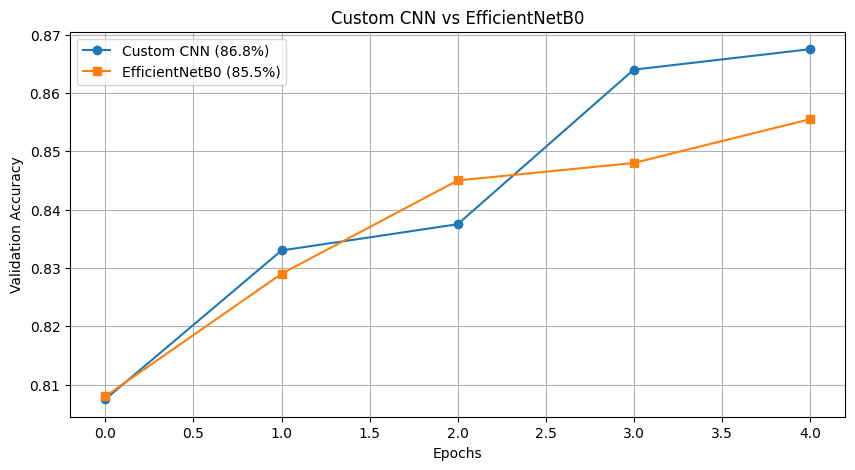

In [7]:
print("=" * 50)
print(f"{'Metric':<20} | {'Custom CNN':<12} | {'EfficientNetB0':<12}")
print("=" * 50)
print(f"{'Test Accuracy':<20} | {acc_cnn*100:>10.2f}% | {acc_eff*100:>10.2f}%")
print(f"{'Test Loss':<20} | {loss_cnn:>11.4f} | {loss_eff:>11.4f}")
print(f"{'Training Time (s)':<20} | {time_cnn:>10.2f}s | {time_eff:>10.2f}s")
print("=" * 50)

plt.figure(figsize=(10, 5))
plt.plot(
    history_cnn.history["val_accuracy"],
    label=f"Custom CNN ({acc_cnn*100:.1f}%)",
    marker="o",
)
plt.plot(
    history_eff.history["val_accuracy"],
    label=f"EfficientNetB0 ({acc_eff*100:.1f}%)",
    marker="s",
)
plt.title("Custom CNN vs EfficientNetB0")
plt.xlabel("Epochs")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.grid(True)

plt.savefig("comparison.png", dpi=300, bbox_inches="tight")
plt.show()